# Malaria Parasite Detection from Blood Cell Images
Computer Vision Lab: image classification with classical features

Dataset: Cell Images for Detecting Malaria (NIH / NLM), https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria

Pipeline: preprocessing, feature extraction (HOG, LBP, GLCM, HSV histogram), feature selection (chi-square, L1), classification (KNN, SVM, Random Forest), evaluation.

## 0. Choice of dataset

**The problem.** Malaria is diagnosed in most clinics by looking at a Giemsa-stained blood smear under a microscope, and a trained technician has to find and count infected red blood cells. That work is slow, tiring and depends on the person doing it. A classifier that labels a single cell as parasitized or uninfected is the basic building block for automating this step, and false negatives matter because a missed infection delays treatment. Malaria is still a public health problem in parts of India, including the north-east, which is why I picked a medical problem with a local connection.

**Why it suits this pipeline.** The dataset was released by the U.S. National Library of Medicine (NIH) and contains 27,558 segmented red blood cell images from thin smear slides, split evenly into two classes (13,779 parasitized and 13,779 uninfected). Each image is a small crop of a single cell (roughly 100 x 100 pixels, sizes vary), so it can be resized to 64 x 64 without losing the parasite. The download is about 340 MB, well under the 2 GB limit. Infected cells differ from healthy ones in stain colour (the purple parasite against pink cytoplasm) and in local texture, which are exactly what HSV histograms, LBP and GLCM describe. Because the classes are balanced and there are only two of them, ROC analysis and error analysis are straightforward to read.

**What makes it hard.** The parasite is often a small dark spot covering a few percent of the cell, so global descriptors can easily miss it. Staining and illumination differ between slides, and some uninfected cells carry stain debris that looks like a parasite. Image sizes are not uniform. The Kaggle copy has no patient or slide identifier, so crops from the same smear can end up in both training and test sets, which makes test scores somewhat optimistic. Finally, the cells are already segmented and cleaned, so real smears would be harder than this benchmark.

**Subset used.** To keep the grid searches at a reasonable running time, I use a stratified random subset of 3,000 images per class (6,000 images in total). The number can be changed in the configuration cell.

## Setup

In [ ]:
import os, random, hashlib, warnings, time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from joblib import Parallel, delayed, Memory

from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, SelectFromModel, chi2
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, auc, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

IMG_SIZE = 64
SUBSET_PER_CLASS = 3000        # None uses all 27,558 images
KAGGLE_HANDLE = "iarunava/cell-images-for-detecting-malaria"

DATA_DIR = os.environ.get("DATA_DIR", None)      # set a local path to skip the download
QUICK_RUN = os.environ.get("QUICK_RUN", "0") == "1"   # smaller grids, for testing the notebook

## 1. Dataset description

In [ ]:
if DATA_DIR is None:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download(KAGGLE_HANDLE)
print("Dataset folder:", DATA_DIR)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
records = [(str(p), p.parent.name) for p in Path(DATA_DIR).rglob("*") if p.suffix.lower() in IMG_EXT]
df_all = pd.DataFrame(records, columns=["path", "label"])

total_mb = sum(os.path.getsize(p) for p in df_all.path) / 1e6
print(f"{len(df_all)} images, {df_all.label.nunique()} classes, {total_mb:,.0f} MB on disk")
print(df_all.label.value_counts())
assert 2 <= df_all.label.nunique() <= 20

Dataset folder: /kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria
55116 images, 2 classes, 664 MB on disk
label
Parasitized    27558
Uninfected     27558
Name: count, dtype: int64


The archive can contain a nested copy of the class folders, so identical files are removed before anything else. Only exact duplicates (same bytes) are detected.

In [ ]:
def file_md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df_all["md5"] = Parallel(n_jobs=-1)(delayed(file_md5)(p) for p in df_all.path)
dup_mask = df_all.duplicated("md5", keep="first")
print("Exact duplicate files:", int(dup_mask.sum()))
print("Hashes found under more than one label:", int((df_all.groupby("md5").label.nunique() > 1).sum()))

df_full = df_all[~dup_mask].reset_index(drop=True)
print("Unique images:", len(df_full))

Exact duplicate files: 27558
Hashes found under more than one label: 0
Unique images: 27558


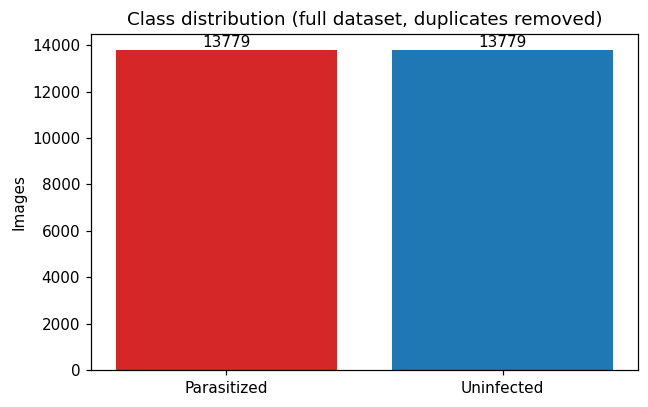

Largest / smallest class: 1.00


In [ ]:
counts = df_full.label.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3.8))
bars = ax.bar(counts.index, counts.values, color=["tab:red", "tab:blue"][:len(counts)] if len(counts) == 2 else None)
ax.bar_label(bars)
ax.set_ylabel("Images")
ax.set_title("Class distribution (full dataset, duplicates removed)")
plt.tight_layout()
plt.show()
print("Largest / smallest class: %.2f" % (counts.max() / counts.min()))

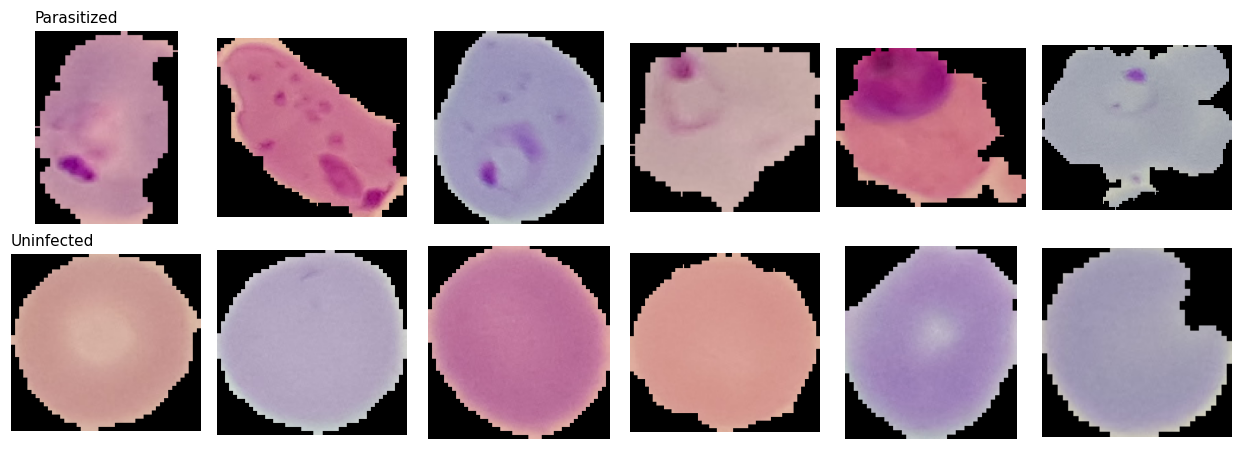

Distinct (width, height) pairs: 1627
Width : min 46, median 130, max 394
Height: min 40, median 130, max 385


In [ ]:
classes_all = sorted(df_full.label.unique())
rng = np.random.RandomState(SEED)
n_per = 6
fig, axes = plt.subplots(len(classes_all), n_per, figsize=(1.9 * n_per, 2.1 * len(classes_all)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes_all):
    paths = df_full[df_full.label == c].path.values
    for k, p in enumerate(rng.choice(paths, n_per, replace=False)):
        axes[r, k].imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
        axes[r, k].axis("off")
    axes[r, 0].set_title(c, fontsize=10, loc="left")
plt.tight_layout()
plt.show()

sizes = [Image.open(p).size for p in df_full.path]
w = np.array([s[0] for s in sizes]); h = np.array([s[1] for s in sizes])
print("Distinct (width, height) pairs:", len(set(sizes)))
print("Width : min %d, median %d, max %d" % (w.min(), np.median(w), w.max()))
print("Height: min %d, median %d, max %d" % (h.min(), np.median(h), h.max()))

| Item | Value |
|---|---|
| Source | https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria (originally from the NIH / National Library of Medicine) |
| Licence | Public domain (NIH / NLM) |
| Classes | Parasitized, Uninfected |
| Images | 27,558 in the original release, 13,779 per class |
| Image size | variable, small single-cell crops (see the output above) |
| Reference | Rajaraman et al., PeerJ 6:e4568, 2018, doi:10.7717/peerj.4568 |

## 2. Subset, split and preprocessing
A stratified random subset is drawn first, then split 70 / 15 / 15 into train, validation and test sets, stratified by class. Nothing is fitted before the split. The training set is used for fitting and for 5-fold cross-validation, the validation set to choose among pipelines, and the test set only for the final report.

Images used: 6000


,train,val,test
label,,,
Parasitized,2100,450,450
Uninfected,2100,450,450
Total,4200,900,900


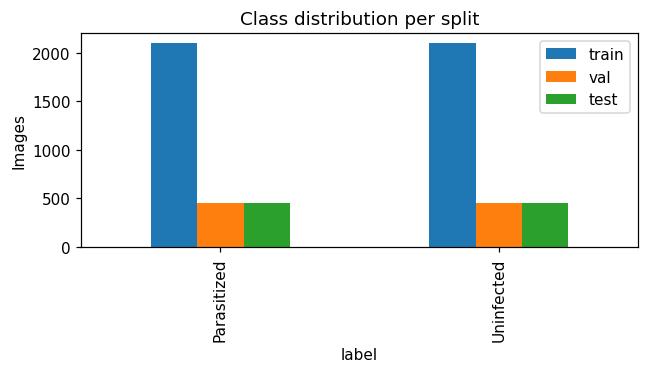

In [ ]:
df = df_full.copy()
if SUBSET_PER_CLASS:
    n = min(SUBSET_PER_CLASS, df.label.value_counts().min())
    df = df.groupby("label").sample(n=n, random_state=SEED).reset_index(drop=True)
print("Images used:", len(df))

le = LabelEncoder()
df["y"] = le.fit_transform(df.label)
CLASSES = list(le.classes_)
N_CLASSES = len(CLASSES)

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.y, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df.y, random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]
y_train, y_val, y_test = train_df.y.values, val_df.y.values, test_df.y.values

split_table = pd.DataFrame({
    "train": train_df.label.value_counts(),
    "val": val_df.label.value_counts(),
    "test": test_df.label.value_counts(),
}).sort_index()
split_table.loc["Total"] = split_table.sum()
display(split_table)

split_table.iloc[:-1].plot(kind="bar", figsize=(6, 3.5), title="Class distribution per split")
plt.ylabel("Images")
plt.tight_layout()
plt.show()

Five preprocessing techniques are used:

1. Resizing to 64 x 64 with area interpolation.
2. Noise filtering with a 3 x 3 median filter.
3. Colour conversion: RGB to LAB (for contrast enhancement), grayscale (HOG, LBP, GLCM) and HSV (colour histograms).
4. Contrast enhancement with CLAHE on the L channel only, so the stain colours are not shifted.
5. Normalisation of pixel values to the range [0, 1].

These operate on one image at a time and learn nothing from the data, so they do not leak information across splits. Feature standardisation, which does need fitting, is done inside the pipelines later.

In [ ]:
def read_rgb(path):
    bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    if bgr is None:
        raise ValueError(f"cannot read {path}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

def step_resize(rgb):
    return cv2.resize(rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

def step_denoise(rgb):
    return cv2.medianBlur(rgb, 3)

def step_clahe(rgb):
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))   # created per-call, no global state
    l, a, b = cv2.split(cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB))
    return cv2.cvtColor(cv2.merge((clahe.apply(l), a, b)), cv2.COLOR_LAB2RGB)

def step_gray_norm(rgb):
    return cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255.0

def preprocess(path):
    return step_clahe(step_denoise(step_resize(read_rgb(path))))

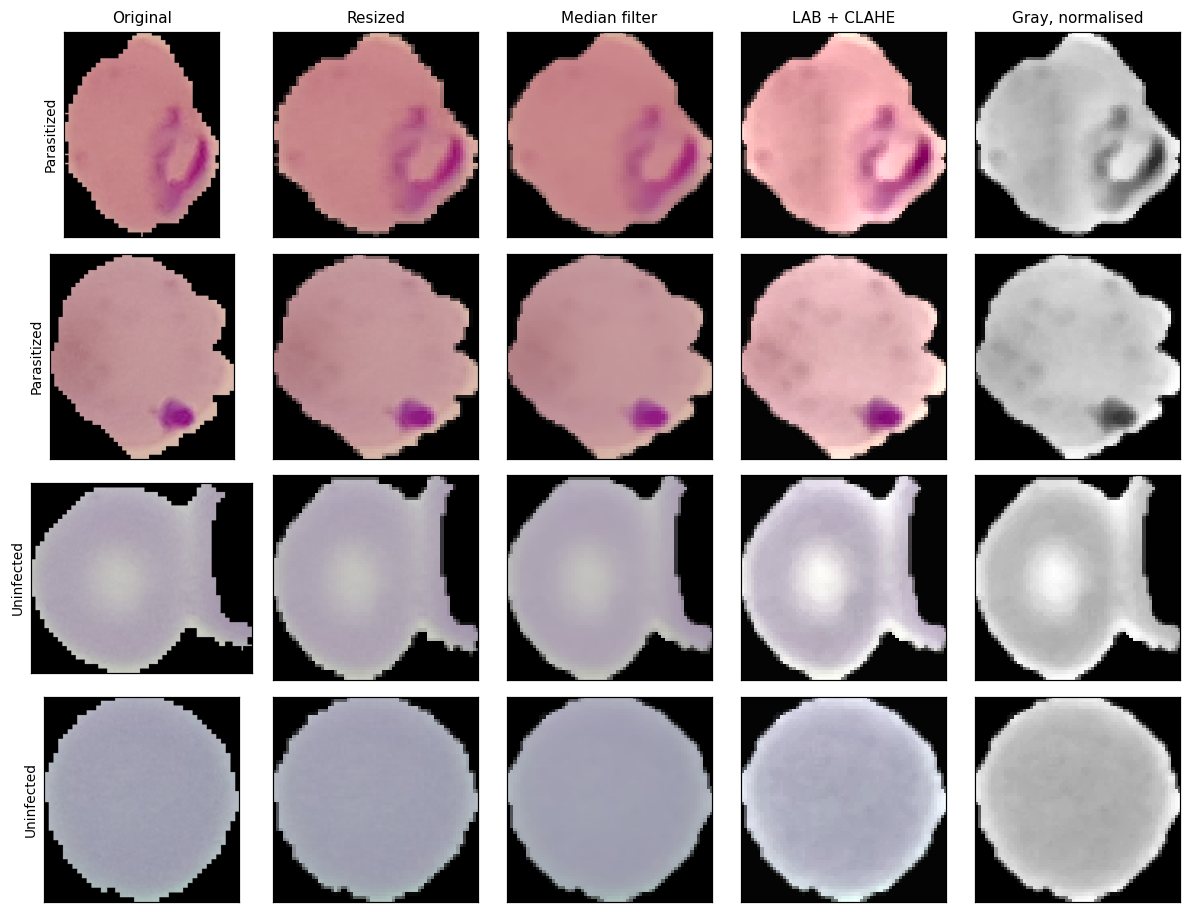

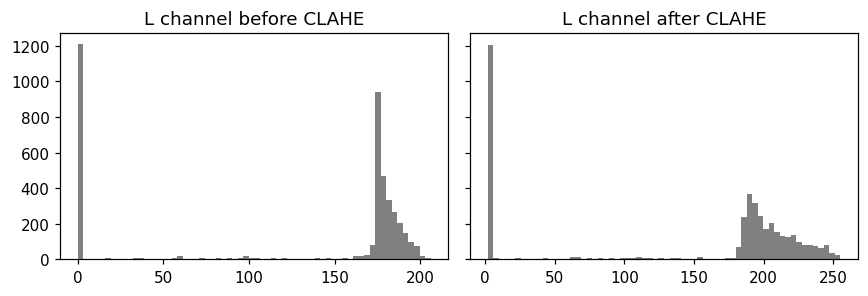

In [ ]:
examples = [(c, i) for c in CLASSES[:3] for i in range(2)]
titles = ["Original", "Resized", "Median filter", "LAB + CLAHE", "Gray, normalised"]

fig, axes = plt.subplots(len(examples), 5, figsize=(11, 2.1 * len(examples)))
for r, (c, i) in enumerate(examples):
    p = train_df[train_df.label == c].path.iloc[i]
    o = read_rgb(p); rs = step_resize(o); dn = step_denoise(rs); cl = step_clahe(dn); gr = step_gray_norm(cl)
    for ax, im in zip(axes[r], [o, rs, dn, cl, gr]):
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None)
        ax.set_xticks([]); ax.set_yticks([])
    axes[r, 0].set_ylabel(c, fontsize=9)
for ax, t in zip(axes[0], titles):
    ax.set_title(t, fontsize=10)
plt.tight_layout()
plt.show()

p = train_df.path.iloc[0]
before = step_denoise(step_resize(read_rgb(p)))
after = step_clahe(before)
fig, ax = plt.subplots(1, 2, figsize=(8, 2.8), sharey=True)
for a, im, t in zip(ax, [before, after], ["L channel before CLAHE", "L channel after CLAHE"]):
    a.hist(cv2.cvtColor(im, cv2.COLOR_RGB2LAB)[..., 0].ravel(), bins=64, color="gray")
    a.set_title(t)
plt.tight_layout()
plt.show()

## 3. Feature extraction and selection

| Feature group | Describes | Computed on |
|---|---|---|
| HOG | local edge orientation and shape | grayscale |
| LBP (uniform, radius 1 and 2) | micro-texture | grayscale |
| GLCM | contrast, dissimilarity, homogeneity, energy, correlation | grayscale, 32 levels |
| HSV histogram | stain colour distribution | HSV |

Extraction is deterministic and works on single images. Feature selection is fitted on training data only, inside the pipelines in Section 4.

In [ ]:
def f_hog(gray_f):
    return hog(gray_f, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2),
               block_norm="L2-Hys", feature_vector=True)

def f_lbp(gray_u8):
    out = []
    for P, R in [(8, 1), (16, 2)]:
        lbp = local_binary_pattern(gray_u8, P, R, method="uniform")
        hist, _ = np.histogram(lbp.ravel(), bins=P + 2, range=(0, P + 2), density=True)
        out.append(hist)
    return np.concatenate(out)

def f_glcm(gray_u8):
    q = (gray_u8 // 8).astype(np.uint8)
    g = graycomatrix(q, distances=[1, 3], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                     levels=32, symmetric=True, normed=True)
    props = ("contrast", "dissimilarity", "homogeneity", "energy", "correlation")
    return np.nan_to_num(np.concatenate([graycoprops(g, p).ravel() for p in props]))

def f_hsv(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    out = []
    for ch, rg in zip(range(3), ([0, 180], [0, 256], [0, 256])):
        h = cv2.calcHist([hsv], [ch], None, [16], rg).ravel()
        out.append(h / (h.sum() + 1e-8))
    return np.concatenate(out)

GROUP_ORDER = ["HOG", "LBP", "GLCM", "HSV"]

def extract_parts(path):
    rgb = preprocess(path)
    gray_u8 = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    gray_f = gray_u8.astype(np.float32) / 255.0
    return {"HOG": f_hog(gray_f), "LBP": f_lbp(gray_u8), "GLCM": f_glcm(gray_u8), "HSV": f_hsv(rgb)}

def extract_one(path):
    parts = extract_parts(path)
    return np.concatenate([parts[g] for g in GROUP_ORDER]).astype(np.float32)

probe = extract_parts(train_df.path.iloc[0])
GROUP_SIZES = {g: len(probe[g]) for g in GROUP_ORDER}
FEATURE_GROUP = np.concatenate([[g] * n for g, n in GROUP_SIZES.items()])
print(GROUP_SIZES, "total:", len(FEATURE_GROUP))

{'HOG': 1764, 'LBP': 28, 'GLCM': 40, 'HSV': 48} total: 1880


In [ ]:
def extract_many(paths):
    return np.vstack(
        Parallel(n_jobs=-1, prefer="threads")(delayed(extract_one)(p) for p in paths)
    )

key = hashlib.md5(("|".join(train_df.path) + "#" + "|".join(val_df.path) + "#" + "|".join(test_df.path)
                   + f"#{IMG_SIZE}").encode()).hexdigest()[:10]
cache_file = f"features_{key}.npz"

if os.path.exists(cache_file):
    z = np.load(cache_file)
    X_train, X_val, X_test = z["X_train"], z["X_val"], z["X_test"]
    print("loaded", cache_file)
else:
    t0 = time.time()
    X_train, X_val, X_test = [extract_many(d.path) for d in (train_df, val_df, test_df)]
    np.savez_compressed(cache_file, X_train=X_train, X_val=X_val, X_test=X_test)
    print(f"extracted in {time.time() - t0:.0f}s")

for name, X in [("train", X_train), ("val", X_val), ("test", X_test)]:
    assert np.isfinite(X).all()
    print(f"X_{name}:", X.shape)

before_tbl = pd.DataFrame({"features": GROUP_SIZES})
before_tbl.loc["Total"] = before_tbl.features.sum()
display(before_tbl)

extracted in 44s
X_train: (4200, 1880)
X_val: (900, 1880)
X_test: (900, 1880)


,features
HOG,1764
LBP,28
GLCM,40
HSV,48
Total,1880


## 4. Classification

Each model is a scikit-learn `Pipeline` of scaler, feature selector and classifier, tuned with 5-fold stratified cross-validation (`GridSearchCV`, scored by macro F1) on the training set only. Because the scaler and selector sit inside the pipeline, they are refitted on each training fold and never see the held-out fold.

- Selectors: chi-square (`SelectKBest`, which needs non-negative input, so it is paired with `MinMaxScaler`), an L1-penalised linear SVM (`SelectFromModel`), and no selection as a baseline. The number of features kept is part of the grid.
- Classifiers: KNN, SVM with RBF kernel, Random Forest.
- This gives 3 x 3 = 9 combinations.

In [ ]:
SELECTORS = {
    "None": dict(scaler=StandardScaler, step="passthrough", grid={}),
    "Chi2": dict(scaler=MinMaxScaler, step=SelectKBest(chi2),
                 grid={"select__k": [50, 200, 500]}),
    "L1-SVM": dict(scaler=StandardScaler,
                   step=SelectFromModel(LinearSVC(penalty="l1", dual=False, max_iter=5000, random_state=SEED)),
                   grid={"select__estimator__C": [0.01, 0.03, 0.1]}),
}

CLASSIFIERS = {
    "KNN": (KNeighborsClassifier(),
            {"clf__n_neighbors": [3, 5, 9, 15], "clf__weights": ["uniform", "distance"]}),
    "SVM-RBF": (SVC(kernel="rbf", probability=True, random_state=SEED),
                {"clf__C": [1, 10, 100], "clf__gamma": ["scale", 1e-3]}),
    "RandomForest": (RandomForestClassifier(random_state=SEED, n_jobs=1),
                     {"clf__n_estimators": [200, 400], "clf__max_depth": [None, 30],
                      "clf__min_samples_leaf": [1, 2]}),
}

def shrink(grid):
    return {k: v[:1] for k, v in grid.items()} if QUICK_RUN else grid

memory = Memory("pipeline_cache", verbose=0)

def build_pipeline(sel_name, clf_name):
    s = SELECTORS[sel_name]
    step = s["step"] if isinstance(s["step"], str) else clone(s["step"])
    return Pipeline([("scale", s["scaler"]()), ("select", step), ("clf", clone(CLASSIFIERS[clf_name][0]))],
                    memory=memory)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [ ]:
fitted = {}
for sel_name in SELECTORS:
    for clf_name in CLASSIFIERS:
        t0 = time.time()
        grid = shrink({**CLASSIFIERS[clf_name][1], **SELECTORS[sel_name]["grid"]})
        gs = GridSearchCV(build_pipeline(sel_name, clf_name), grid, cv=cv, scoring="f1_macro",
                          n_jobs=-1, refit=True)
        gs.fit(X_train, y_train)
        fitted[(sel_name, clf_name)] = gs
        print(f"{sel_name:7s} + {clf_name:12s} CV macro-F1 {gs.best_score_:.4f}  ({time.time() - t0:.0f}s)  {gs.best_params_}")

None    + KNN          CV macro-F1 0.6149  (9s)  {'clf__n_neighbors': 3, 'clf__weights': 'uniform'}
None    + SVM-RBF      CV macro-F1 0.8726  (1039s)  {'clf__C': 10, 'clf__gamma': 'scale'}
None    + RandomForest CV macro-F1 0.9452  (708s)  {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200}
Chi2    + KNN          CV macro-F1 0.8001  (8s)  {'clf__n_neighbors': 15, 'clf__weights': 'uniform', 'select__k': 50}
Chi2    + SVM-RBF      CV macro-F1 0.8512  (249s)  {'clf__C': 100, 'clf__gamma': 0.001, 'select__k': 200}
Chi2    + RandomForest CV macro-F1 0.9450  (578s)  {'clf__max_depth': 30, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200, 'select__k': 500}
L1-SVM  + KNN          CV macro-F1 0.7352  (149s)  {'clf__n_neighbors': 3, 'clf__weights': 'uniform', 'select__estimator__C': 0.01}
L1-SVM  + SVM-RBF      CV macro-F1 0.8750  (478s)  {'clf__C': 10, 'clf__gamma': 0.001, 'select__estimator__C': 0.01}
L1-SVM  + RandomForest CV macro-F1 0.9455  (955s)  {'clf__max

In [ ]:
def selected_mask(gs):
    sel = gs.best_estimator_.named_steps["select"]
    return np.ones(X_train.shape[1], dtype=bool) if isinstance(sel, str) else sel.get_support()

rows = []
for (sel_name, clf_name), gs in fitted.items():
    m = selected_mask(gs)
    row = {"Selector": sel_name, "Classifier": clf_name,
           "Features before": X_train.shape[1], "Features after": int(m.sum())}
    for g in GROUP_ORDER:
        row[f"kept {g}"] = int(m[FEATURE_GROUP == g].sum())
    rows.append(row)
selection_table = pd.DataFrame(rows)
display(selection_table)

,Selector,Classifier,Features before,Features after,kept HOG,kept LBP,kept GLCM,kept HSV
0,None,KNN,1880,1880,1764,28,40,48
1,None,SVM-RBF,1880,1880,1764,28,40,48
2,None,RandomForest,1880,1880,1764,28,40,48
3,Chi2,KNN,1880,50,27,9,4,10
4,Chi2,SVM-RBF,1880,200,158,12,14,16
5,Chi2,RandomForest,1880,500,439,17,24,20
6,L1-SVM,KNN,1880,214,173,13,7,21
7,L1-SVM,SVM-RBF,1880,214,173,13,7,21
8,L1-SVM,RandomForest,1880,873,799,17,17,40


## 5. Performance evaluation

The validation set is used to pick the best of the nine pipelines. The test set is then used to report accuracy, macro precision, macro recall, macro F1 and ROC-AUC for every combination.

In [ ]:
def auc_score(y, proba):
    if N_CLASSES == 2:
        return roc_auc_score(y, proba[:, 1])
    return roc_auc_score(y, proba, multi_class="ovr", average="macro")

def evaluate(model, X, y):
    pred = model.predict(X)
    proba = model.predict_proba(X)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, average="macro", zero_division=0),
        "Recall": recall_score(y, pred, average="macro", zero_division=0),
        "F1": f1_score(y, pred, average="macro", zero_division=0),
        "AUC": auc_score(y, proba),
    }, pred, proba

preds_test, probas_test, table = {}, {}, []
for (sel_name, clf_name), gs in fitted.items():
    val_m, _, _ = evaluate(gs.best_estimator_, X_val, y_val)
    test_m, p, pr = evaluate(gs.best_estimator_, X_test, y_test)
    preds_test[(sel_name, clf_name)], probas_test[(sel_name, clf_name)] = p, pr
    table.append({
        "Selector": sel_name, "Classifier": clf_name,
        "Features": int(selected_mask(gs).sum()),
        "CV F1": gs.best_score_, "Val F1": val_m["F1"],
        "Test Accuracy": test_m["Accuracy"], "Test Precision": test_m["Precision"],
        "Test Recall": test_m["Recall"], "Test F1": test_m["F1"], "Test AUC": test_m["AUC"],
        "Best params": str(gs.best_params_),
    })

results = pd.DataFrame(table).sort_values("Val F1", ascending=False).reset_index(drop=True)
results.to_csv("results_all_combinations.csv", index=False)
num_cols = [c for c in results.columns if c not in ("Selector", "Classifier", "Features", "Best params")]
display(results.style.format({c: "{:.4f}" for c in num_cols}).highlight_max(subset=num_cols, color="lightgreen"))

best_key = (results.loc[0, "Selector"], results.loc[0, "Classifier"])
print("Best pipeline by validation F1:", best_key)

,Selector,Classifier,Features,CV F1,Val F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test AUC,Best params
0,L1-SVM,RandomForest,873,0.9455,0.9467,0.9422,0.9425,0.9422,0.9422,0.9872,"{'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 400, 'select__estimator__C': 0.1}"
1,Chi2,RandomForest,500,0.9450,0.9444,0.9433,0.9438,0.9433,0.9433,0.9868,"{'clf__max_depth': 30, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200, 'select__k': 500}"
2,None,RandomForest,1880,0.9452,0.9444,0.9433,0.9434,0.9433,0.9433,0.9863,"{'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200}"
3,L1-SVM,SVM-RBF,214,0.8750,0.8955,0.8844,0.8855,0.8844,0.8844,0.9575,"{'clf__C': 10, 'clf__gamma': 0.001, 'select__estimator__C': 0.01}"
4,None,SVM-RBF,1880,0.8726,0.8855,0.8911,0.8912,0.8911,0.8911,0.9582,"{'clf__C': 10, 'clf__gamma': 'scale'}"
5,Chi2,SVM-RBF,200,0.8512,0.8578,0.8667,0.8667,0.8667,0.8667,0.9345,"{'clf__C': 100, 'clf__gamma': 0.001, 'select__k': 200}"
6,Chi2,KNN,50,0.8001,0.8132,0.8178,0.8211,0.8178,0.8173,0.9090,"{'clf__n_neighbors': 15, 'clf__weights': 'uniform', 'select__k': 50}"
7,L1-SVM,KNN,214,0.7352,0.7442,0.7400,0.7718,0.7400,0.7322,0.8468,"{'clf__n_neighbors': 3, 'clf__weights': 'uniform', 'select__estimator__C': 0.01}"
8,None,KNN,1880,0.6149,0.6335,0.6622,0.7346,0.6622,0.6340,0.7668,"{'clf__n_neighbors': 3, 'clf__weights': 'uniform'}"


Best pipeline by validation F1: ('L1-SVM', 'RandomForest')


L1-SVM + RandomForest: 873 of 1880 features kept

              precision    recall  f1-score   support

 Parasitized     0.9543    0.9289    0.9414       450
  Uninfected     0.9307    0.9556    0.9430       450

    accuracy                         0.9422       900
   macro avg     0.9425    0.9422    0.9422       900
weighted avg     0.9425    0.9422    0.9422       900



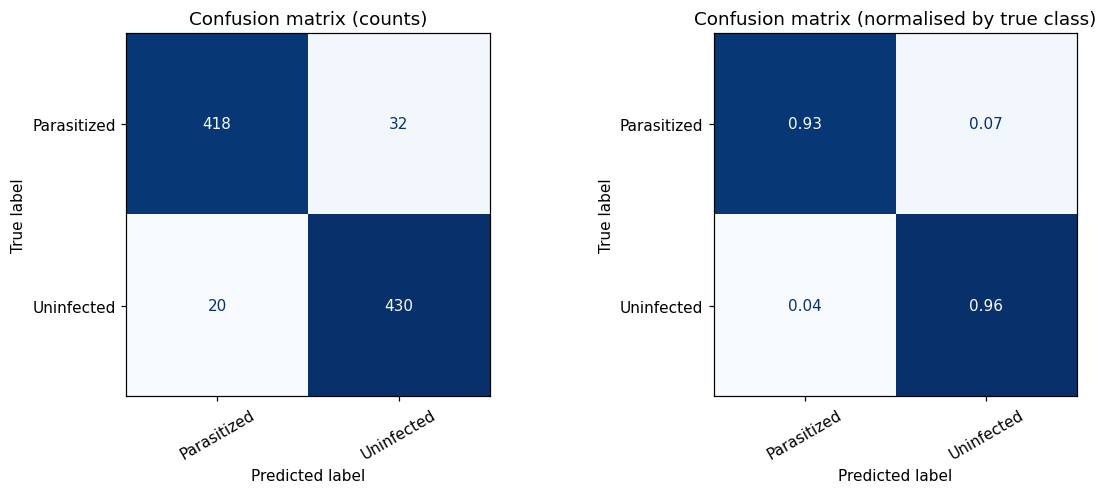

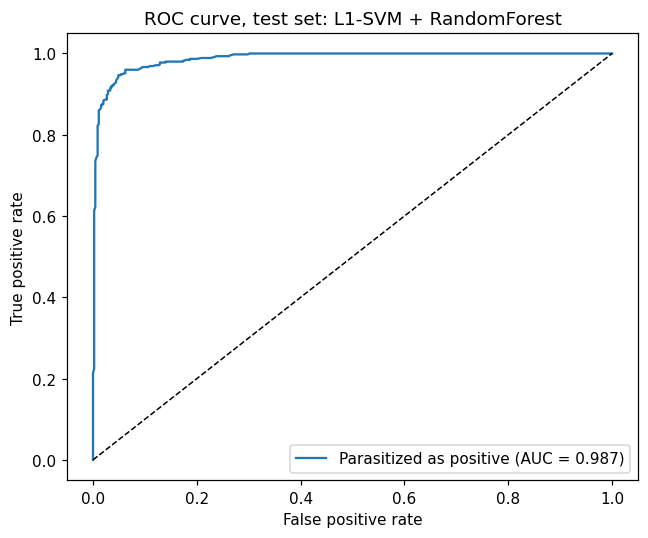

AUC: 0.9872


In [ ]:
best_gs = fitted[best_key]
pred, proba = preds_test[best_key], probas_test[best_key]

print(f"{best_key[0]} + {best_key[1]}: {selected_mask(best_gs).sum()} of {X_train.shape[1]} features kept\n")
print(classification_report(y_test, pred, target_names=CLASSES, digits=4, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=CLASSES, cmap="Blues",
                                        xticks_rotation=30, ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=CLASSES, cmap="Blues",
                                        xticks_rotation=30, normalize="true", values_format=".2f",
                                        ax=ax[1], colorbar=False)
ax[1].set_title("Confusion matrix (normalised by true class)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
if N_CLASSES == 2:
    fpr, tpr, _ = roc_curve(y_test == 0, proba[:, 0])
    plt.plot(fpr, tpr, label=f"{CLASSES[0]} as positive (AUC = {auc(fpr, tpr):.3f})")
else:
    Y = label_binarize(y_test, classes=list(range(N_CLASSES)))
    for i, c in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(Y[:, i], proba[:, i])
        plt.plot(fpr, tpr, label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title(f"ROC curve, test set: {best_key[0]} + {best_key[1]}")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()
print("AUC: %.4f" % auc_score(y_test, proba))

,total,kept,% kept
HOG,1764,799,45.3
LBP,28,17,60.7
GLCM,40,17,42.5
HSV,48,40,83.3


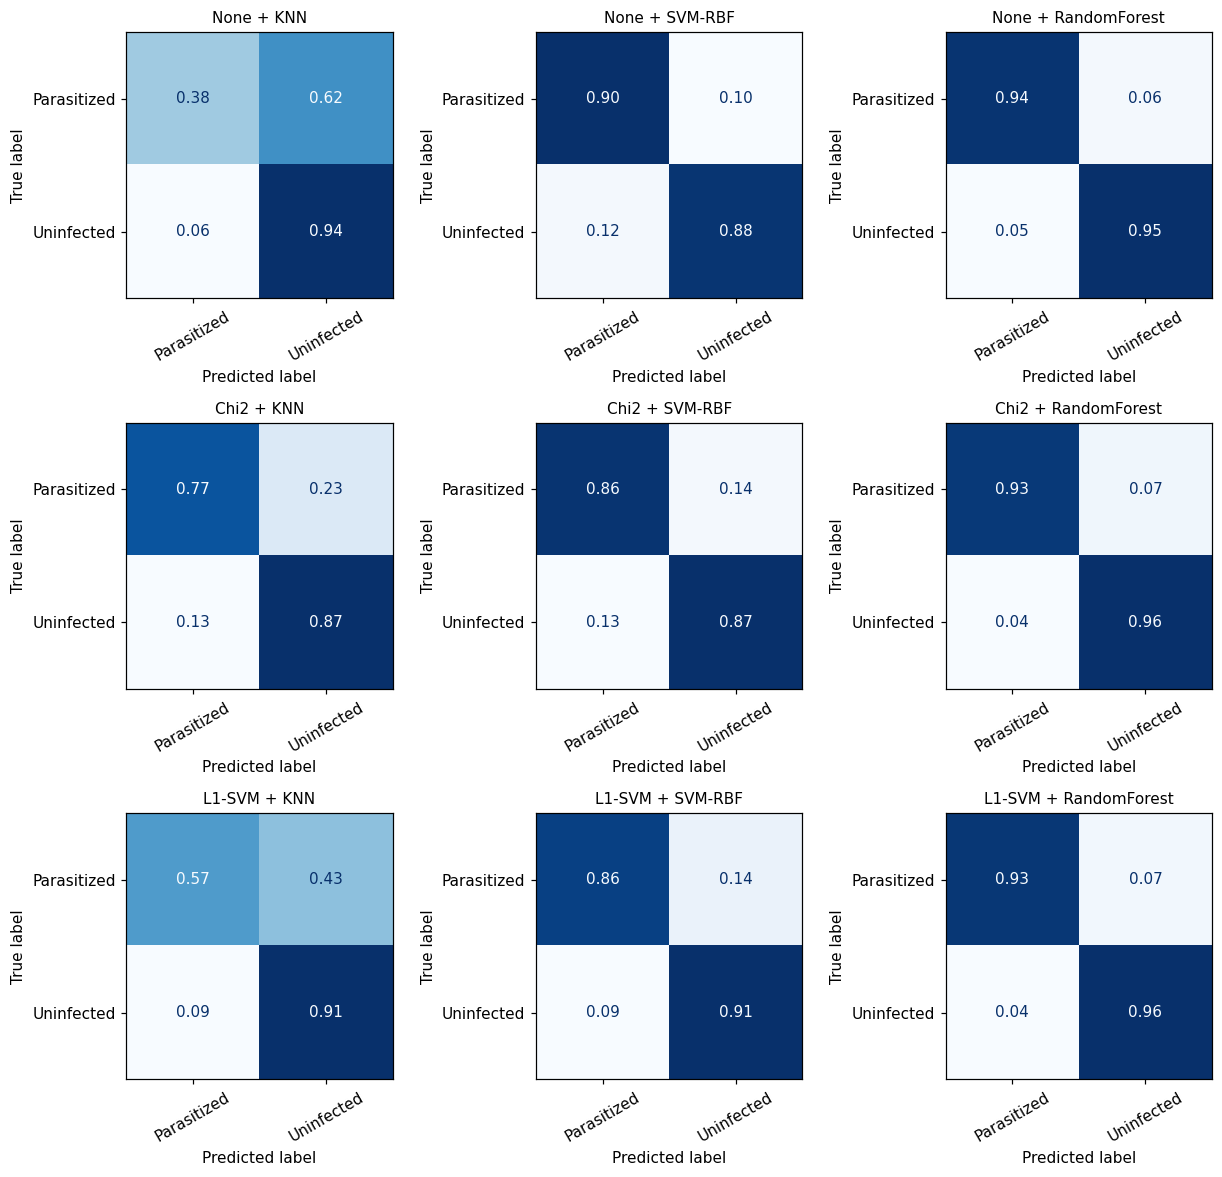

In [ ]:
m = selected_mask(best_gs)
kept = pd.DataFrame({"total": pd.Series(GROUP_SIZES),
                     "kept": pd.Series({g: int(m[FEATURE_GROUP == g].sum()) for g in GROUP_ORDER})})
kept["% kept"] = (100 * kept.kept / kept.total).round(1)
display(kept)

fig, axes = plt.subplots(len(SELECTORS), len(CLASSIFIERS), figsize=(3.8 * len(CLASSIFIERS), 3.6 * len(SELECTORS)))
for r, s in enumerate(SELECTORS):
    for c, k in enumerate(CLASSIFIERS):
        ConfusionMatrixDisplay.from_predictions(y_test, preds_test[(s, k)], display_labels=CLASSES,
                                                normalize="true", values_format=".2f", cmap="Blues",
                                                xticks_rotation=30, ax=axes[r, c], colorbar=False)
        axes[r, c].set_title(f"{s} + {k}", fontsize=10)
plt.tight_layout()
plt.show()

Most frequent confusions (true, predicted, count):
  Parasitized  -> Uninfected   32
  Uninfected   -> Parasitized  20

52 of 900 test images misclassified


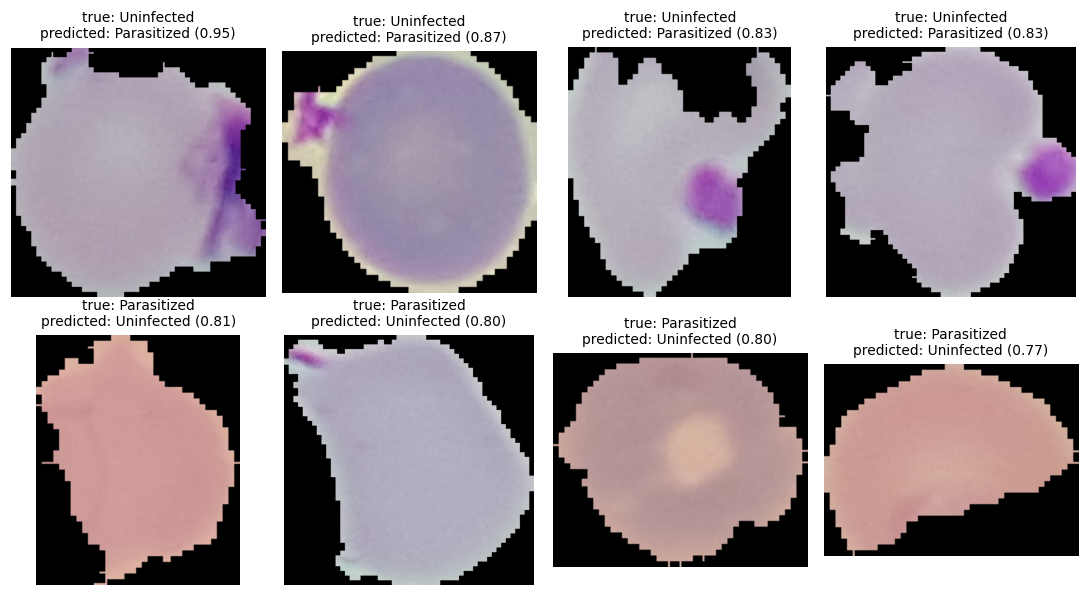

In [ ]:
cm = confusion_matrix(y_test, pred)
pairs = [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(N_CLASSES) for j in range(N_CLASSES)
         if i != j and cm[i, j] > 0]
pairs.sort(key=lambda t: -t[2])
print("Most frequent confusions (true, predicted, count):")
for t, p_, n in pairs[:8]:
    print(f"  {t:12s} -> {p_:12s} {n}")

wrong = np.where(pred != y_test)[0]
print(f"\n{len(wrong)} of {len(y_test)} test images misclassified")
show = wrong[np.argsort(-proba[wrong].max(axis=1))][:8]
if len(show):
    fig, axes = plt.subplots(2, 4, figsize=(10, 5.5))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, idx in zip(axes.ravel(), show):
        ax.imshow(read_rgb(test_df.path[idx]))
        ax.set_title(f"true: {CLASSES[y_test[idx]]}\npredicted: {CLASSES[pred[idx]]} ({proba[idx].max():.2f})", fontsize=9)
    plt.tight_layout()
    plt.show()

## References

- Rajaraman, S., Antani, S. K., Poostchi, M., Silamut, K., Hossain, M. A., Maude, R. J., Jaeger, S., Thoma, G. R. (2018). Pre-trained convolutional neural networks as feature extractors toward improved malaria parasite detection in thin blood smear images. PeerJ 6:e4568. https://doi.org/10.7717/peerj.4568
- Cell Images for Detecting Malaria (Kaggle copy of the NIH / NLM data). https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria
- Pedregosa et al. (2011). Scikit-learn: Machine Learning in Python. JMLR 12, 2825-2830.
- van der Walt et al. (2014). scikit-image: image processing in Python. PeerJ 2:e453.
- Bradski (2000). The OpenCV Library. Dr. Dobb's Journal of Software Tools.